In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
import warnings

df = pd.read_csv('Titanic-Dataset.csv', encoding='UTF-8')

print(df.shape)
print(df.dtypes)

(891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [2]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print(df.isnull().sum())

print("\nКоличество дубликатов:", df.duplicated().sum())

print("\nРаспределение целевой переменной:")
df['Survived'].value_counts()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Количество дубликатов: 0

Распределение целевой переменной:


Survived
0    549
1    342
Name: count, dtype: int64

/tmp/ipykernel_34756/1635912916.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Survived', ax=axes[0], palette=['pink', 'darkred'])


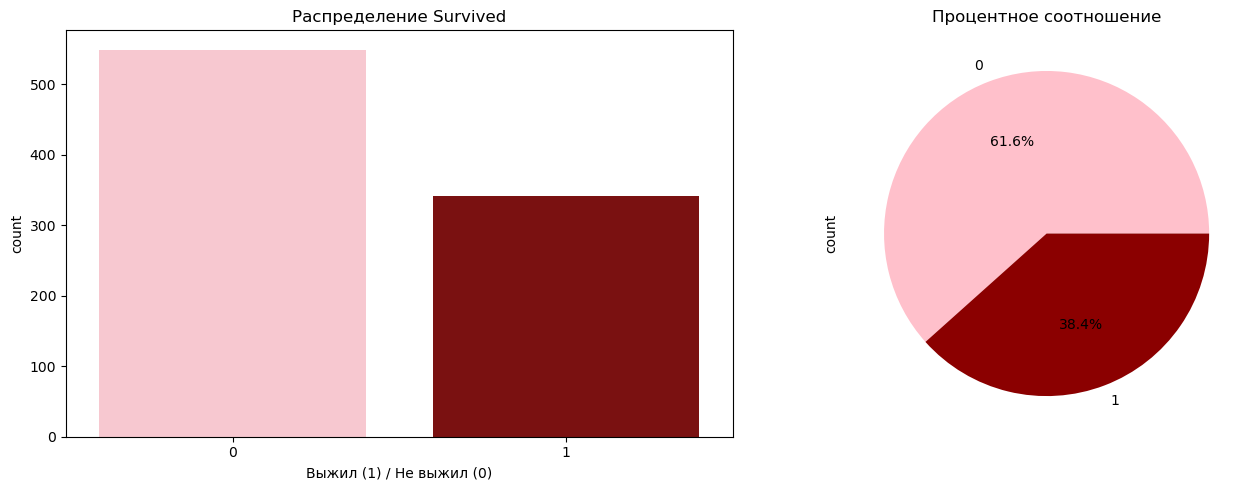

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='Survived', ax=axes[0], palette=['pink', 'darkred'])
axes[0].set_title('Распределение Survived')
axes[0].set_xlabel('Выжил (1) / Не выжил (0)')

df['Survived'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[1], colors=['pink', 'darkred'])
axes[1].set_title('Процентное соотношение')

plt.tight_layout()

In [5]:
print(f"Пропусков в Cabin: {(df['Cabin'].isnull().sum()/len(df)).round(4)}%")

Пропусков в Cabin: 0.771%


## Почему мы не рассматриваем признак `Cabin`

**1. Слишком много пропусков:** 687 из 891 записей (77%) — заполнять «наугад» бессмысленно, это внесёт шум в модель.

**2. Почти уникальные значения:** среди 204 заполненных — 147 разных кают. Признак работает как идентификатор, а не как полезная характеристика → риск переобучения.

**Вывод:** признак не рассматриваем в качестве категориального.

In [6]:
categorical_cols = ['Pclass', 'Sex', 'Embarked']
for col in categorical_cols:
    print(df[col].value_counts())

Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Sex
male      577
female    314
Name: count, dtype: int64
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


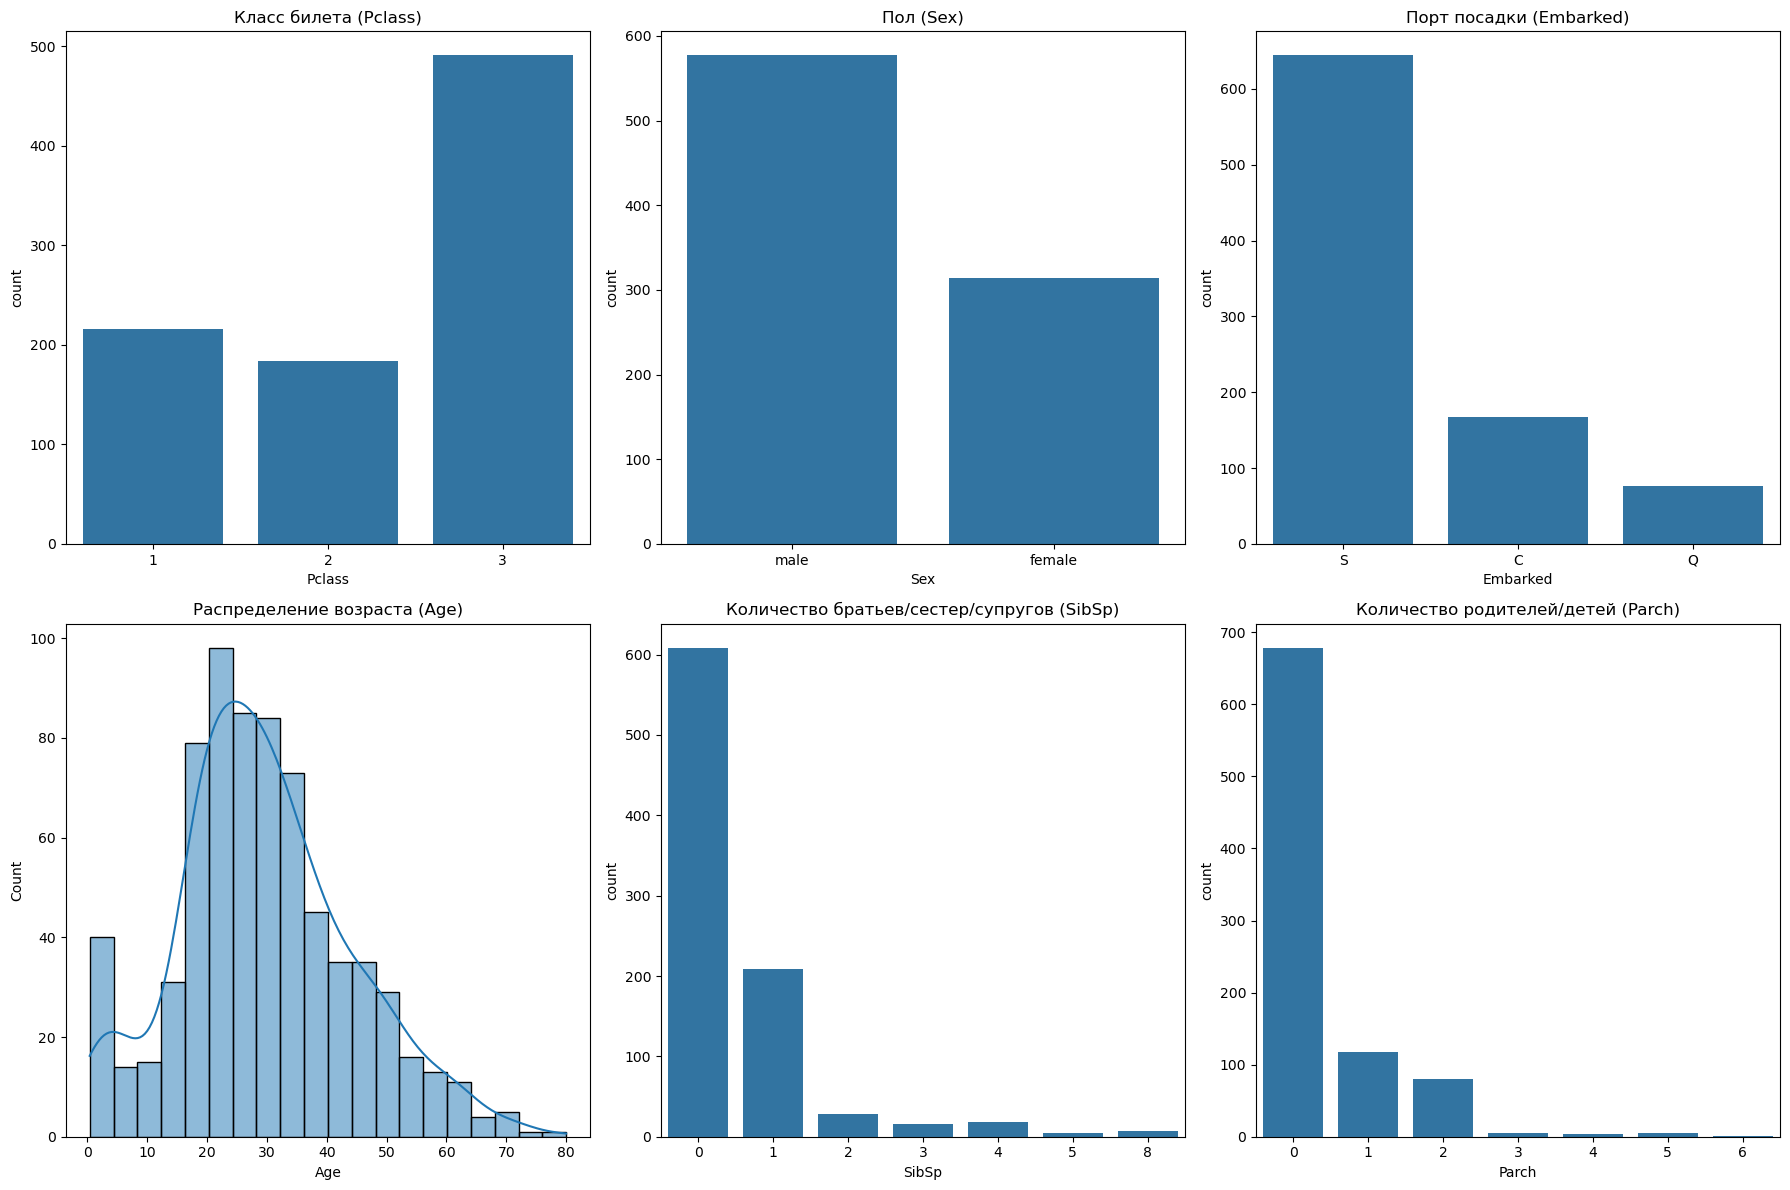

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Pclass
sns.countplot(data=df, x='Pclass', ax=axes[0, 0],)
axes[0, 0].set_title('Класс билета (Pclass)')

# Sex
sns.countplot(data=df, x='Sex', ax=axes[0, 1])
axes[0, 1].set_title('Пол (Sex)')

# Embarked
sns.countplot(data=df, x='Embarked', ax=axes[0, 2])
axes[0, 2].set_title('Порт посадки (Embarked)')

# Age
sns.histplot(data=df, x='Age', kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Распределение возраста (Age)')

# SibSp
sns.countplot(data=df, x='SibSp', ax=axes[1, 1])
axes[1, 1].set_title('Количество братьев/сестер/супругов (SibSp)')

# Parch
sns.countplot(data=df, x='Parch', ax=axes[1, 2])
axes[1, 2].set_title('Количество родителей/детей (Parch)')

plt.tight_layout()

## Краткие выводы по первичному анализу данных

**1. Общая информация о датасете**

Датасет содержит **891 запись** и **12 признаков**. Дубликатов строк не обнаружено. Среди признаков присутствуют как числовые (`int64`, `float64`), так и категориальные (`object`).

**2. Целевая переменная `Survived`**

Распределение классов **несбалансировано**:
- Не выжили (0): 549 пассажиров (**61.6%**)
- Выжили (1): 342 пассажира (**38.4%**)

Это важно учитывать при выборе метрик: простая Accuracy может вводить в заблуждение, поэтому основной метрикой работы будет **F1-score**.

**3. Пропуски в данных**

| Признак | Пропусков | Доля | Решение |
|---|---|---|---|
| `Age` | 177 | 20% | Заполнить **медианой** (устойчива к выбросам) |
| `Embarked` | 2 | 0.2% | Заполнить **модой** (наиболее частое значение) |
| `Cabin` | 687 | **77%** | **Удалить** — слишком много пропусков, заполнение внесёт шум |

**4. Признаки, которые удаляем**

- `PassengerId` — порядковый номер пассажира, не несёт информации о выживаемости
- `Name` — уникально для каждого пассажира (891 уникальное значение), модель просто запомнит данные → переобучение
- `Ticket` — номер билета, почти уникален (681 значение), аналогично ведёт к переобучению
- `Cabin` — 77% пропусков + 147 уникальных значений среди оставшихся, использовать нельзя без сложной дополнительной обработки

> Использование признаков-идентификаторов (`Name`, `Ticket`, `PassengerId`) приводит к **утечке информации** — модель «запоминает» конкретные объекты вместо выявления общих закономерностей.

**5. Категориальные признаки для анализа**

`Pclass`, `Sex`, `Embarked` — имеют малое число уникальных значений (2–3), практически без пропусков, несут понятный смысл (класс обслуживания, пол, порт посадки). Требуют **кодирования** перед обучением модели, так как алгоритмы работают только с числами.

**6. Числовые признаки**

- `Age`, `Fare` — непрерывные, анализируются через гистограммы, boxplot и корреляцию с целевой переменной
- `SibSp`, `Parch` — дискретные счётные (количество родственников), можно рассматривать и как числовые, и как категориальные

**7. Признаки, требующие особой обработки**

- `Sex`, `Embarked` — категориальные, требуют кодирования
- `Pclass` — формально числовой (1, 2, 3), но по смыслу категориальный (класс обслуживания), нельзя трактовать как «больше/меньше»
- `Age`, `Fare` — требуют масштабирования для алгоритмов, основанных на расстояниях (SVM, KNN)

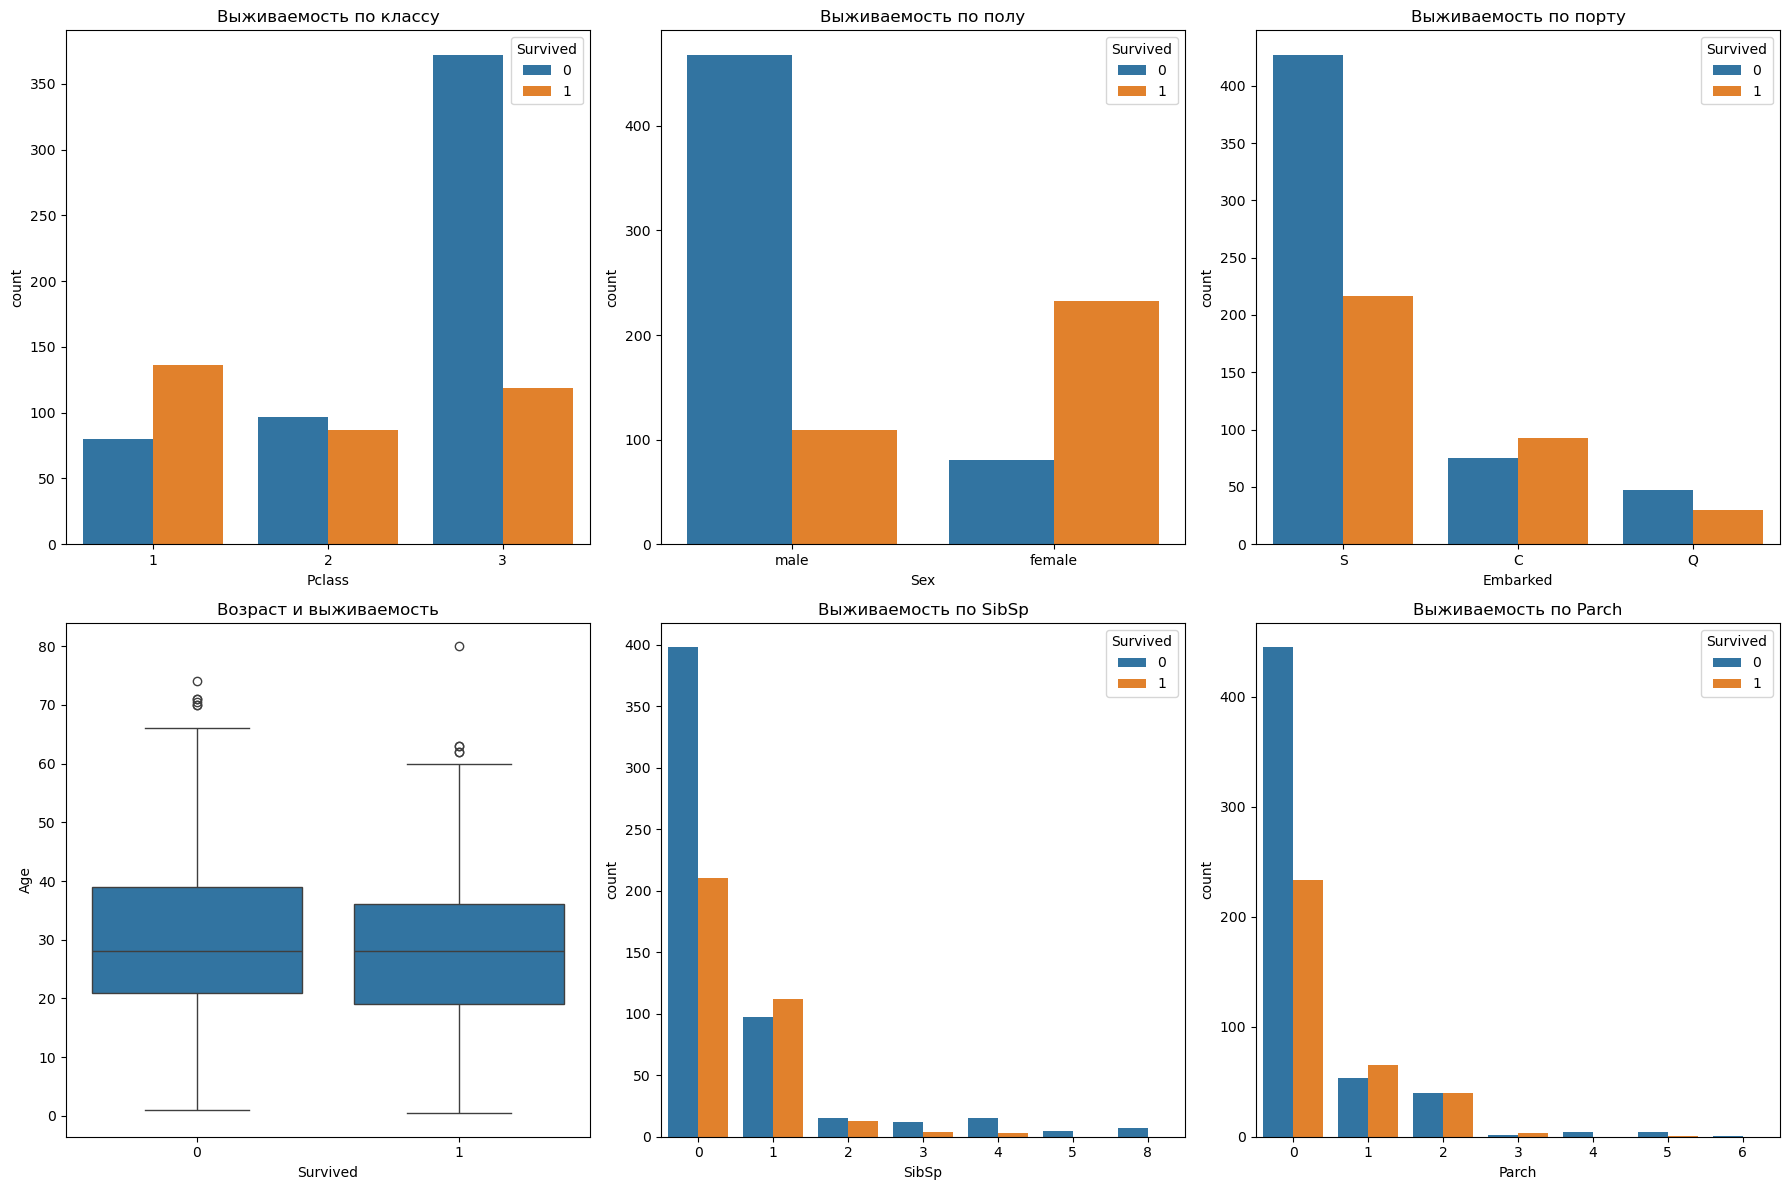

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Pclass vs Survived
sns.countplot(data=df, x='Pclass', hue='Survived', ax=axes[0, 0])
axes[0, 0].set_title('Выживаемость по классу')

# Sex vs Survived
sns.countplot(data=df, x='Sex', hue='Survived', ax=axes[0, 1])
axes[0, 1].set_title('Выживаемость по полу')

# Embarked vs Survived
sns.countplot(data=df, x='Embarked', hue='Survived', ax=axes[0, 2])
axes[0, 2].set_title('Выживаемость по порту')

# Age vs Survived
sns.boxplot(data=df, x='Survived', y='Age', ax=axes[1, 0])
axes[1, 0].set_title('Возраст и выживаемость')

# SibSp vs Survived
sns.countplot(data=df, x='SibSp', hue='Survived', ax=axes[1, 1])
axes[1, 1].set_title('Выживаемость по SibSp')

# Parch vs Survived
sns.countplot(data=df, x='Parch', hue='Survived', ax=axes[1, 2])
axes[1, 2].set_title('Выживаемость по Parch')

plt.tight_layout()

## Анализ взаимосвязи признаков с целевой переменной

По графикам можно сделать следующие предположения о влиянии признаков на выживаемость:

### Сильная связь 

**1. Sex (Пол)** — самый сильный предиктор:
- Женщины: ~74% выживаемости
- Мужчины: ~19% выживаемости
- Принцип «women and children first» работал

**2. Pclass (Класс билета)** — очень сильная связь:
- 1 класс: ~62% выжили
- 2 класс: ~47% выжили  
- 3 класс: ~24% выжили
- Пассажиры 1-го класса имели приоритетный доступ к шлюпкам

### Слабая связь 

**3. Age (Возраст)**:
- Ящики с усами почти одинаковые, можно предположить, что статистически значимых различий нет
- Межквартильные размахи и медианы обеих категорий находятся примерно в одних и тех же диапазонах

**4. Embarked (Порт посадки)**:
- Порт C (Cherbourg): ~56% выживаемости
- Порты S и Q: ~34-38%
- Вероятно, связано с тем, что в C садились более состоятельные пассажиры

**5. SibSp и Parch (Количество родственников)**:
- Пассажиры с 1-2 родственниками выживали чаще (~50-55%)
- Одиночки и большие семьи выживали реже
- Маленькие семьи помогали друг другу, большие — мешали

### Вывод

**Наиболее важные признаки для модели:** `Sex`, `Pclass`. Именно они будут давать основной вклад в предсказание выживаемости.

### Почему признак `Age` оставлен в модели, несмотря на слабую визуальную связь

Несмотря на то, что медианы и межквартильные размахи возраста для выживших и не выживших на boxplot близки, признак `Age` **не был удалён** по следующим причинам:

1. **Нелинейная зависимость:** Boxplot усредняет данные по взрослой группе (основная масса пассажиров). Однако исторически и статистически дети (Age < 12) имели значительно более высокий шанс на спасение, а пожилые люди — более низкий. 
2. **Возможности алгоритмов:** Древовидные модели (Decision Tree, Random Forest) способны выявлять нелинейные пороговые значения (например, разделение на `Age < 12` и `Age >= 12`), которые не видны при простом сравнении медиан.
3. **Эмпирическое подтверждение:** Предварительные тесты показывают, что исключение признака `Age` приводит к снижению метрик качества модели (F1-score и Accuracy), что подтверждает его информативность.

### Почему признаки со слабой связью (Embarked, SibSp, Parch) оставлены в модели

Несмотря на слабую визуальную связь с целевой переменной, эти признаки **не были удалены** по следующим причинам:

1. **Слабая связь ≠ нулевая связь.** Даже небольшой вклад признака может улучшить метрики модели на 1-3%, что критично для преодоления порога качества (F1 > 0.70).

2. **Взаимодействие признаков (feature interaction).** Признаки могут работать синергетически.

3. **Принцип "лучше оставить, чем потерять".** Удаление признака — это безвозвратная потеря информации. Даже если вклад мал, модель сама решит, насколько он важен (через feature importance). Алгоритмы вроде Random Forest и Gradient Boosting устойчивы к слабым признакам и просто присвоят им низкий вес.

4. 
**Вывод:** Признаки `Embarked`, `SibSp`, `Parch` оставлены в модели. Их реальная важность будет оценена после обучения через анализ feature importance.

In [9]:
df_processed = df.copy()

df_processed = df_processed.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)

print("После удаления ненужных признаков:")
print(df_processed.head())
print("\nРазмер:", df_processed.shape)

После удаления ненужных признаков:
   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S

Размер: (891, 8)


In [10]:
print("Пропуски до обработки:")
print(df_processed.isnull().sum())

median_age = df_processed['Age'].median()
df_processed['Age'] = df_processed['Age'].fillna(median_age)

mode_embarked = df_processed['Embarked'].mode()[0]
df_processed['Embarked'] = df_processed['Embarked'].fillna(mode_embarked)

print("\nПропуски после обработки:")
print(df_processed.isnull().sum())

Пропуски до обработки:
Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

Пропуски после обработки:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [11]:
df_processed['Sex'] = df_processed['Sex'].map({'male': 0, 'female': 1})

df_processed = pd.get_dummies(df_processed, columns=['Embarked'], prefix='Embarked', drop_first=True)

print("После кодирования:")
print(df_processed.head())
print("\nРазмер:", df_processed.shape)
print("\nТипы данных:")
print(df_processed.dtypes)

После кодирования:
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked_Q  Embarked_S
0         0       3    0  22.0      1      0   7.2500       False        True
1         1       1    1  38.0      1      0  71.2833       False       False
2         1       3    1  26.0      0      0   7.9250       False        True
3         1       1    1  35.0      1      0  53.1000       False        True
4         0       3    0  35.0      0      0   8.0500       False        True

Размер: (891, 9)

Типы данных:
Survived        int64
Pclass          int64
Sex             int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Embarked_Q       bool
Embarked_S       bool
dtype: object


In [12]:
X = df_processed.drop('Survived', axis=1)
y = df_processed['Survived']

## Подготовка данных и кодирование

### 1. Удаление ненужных признаков

Удалены признаки, которые не несут полезной информации или могут привести к переобучению:
- `PassengerId` — уникальный идентификатор
- `Name` — уникальное имя каждого пассажира
- `Ticket` — номер билета (почти уникальный)
- `Cabin` — 77% пропусков, почти уникальные значения

**Результат:** 891 запись, 8 признаков (включая целевую переменную).

### 2. Обработка пропусков

| Признак | Пропусков | Метод заполнения | Обоснование |
|---------|-----------|------------------|-------------|
| `Age` | 177 (20%) | Медиана | Устойчива к выбросам в отличие от среднего |
| `Embarked` | 2 (0.2%) | Мода | Наиболее частое значение (S) |

После обработки пропусков не осталось.

### 3. Кодирование категориальных признаков

Модели машинного обучения работают только с числами, поэтому категориальные признаки были преобразованы:

**Sex (бинарное кодирование):**
- `male` → 0, `female` → 1
- Подходит для признаков с двумя категориями

**Embarked (One-Hot Encoding):**
```python
df_processed = pd.get_dummies(df_processed, columns=['Embarked'], prefix='Embarked', drop_first=True)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Масштабирование признаков

**Зачем нужно:** некоторые алгоритмы чувствительны к масштабу признаков, потому что используют расстояния между объектами.

| Алгоритм | Масштабирование | Причина |
|---|---|---|
| **SVM** | ✅ Нужно | Основан на расстояниях между точками; признак с большим диапазоном (Fare: 0–500) будет доминировать над признаком с малым (Pclass: 1–3) |
| **KNN** | ✅ Нужно | Считает расстояние между объектами; без масштабирования Fare "перекричит" все остальные признаки |
| **Decision Tree** | ❌ Не нужно | Работает через пороговые значения, масштаб не влияет |
| **Random Forest** | ❌ Не нужно | Ансамбль деревьев, масштаб не важен |
| **Gradient Boosting** |  Не нужно | То же, что и деревья |

**Важно:** `fit` выполняется **только на обучающей выборке**, `transform` — на тестовой. Это предотвращает утечку информации из теста в обучение.

In [15]:
dummy_clf = DummyClassifier(strategy='most_frequent', random_state=42)
dummy_clf.fit(X_train, y_train)
y_pred_dummy = dummy_clf.predict(X_test)

print("Baseline модель (Dummy Classifier)")
print("=" * 50)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_dummy):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dummy):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_dummy):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_dummy):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dummy))

Baseline модель (Dummy Classifier)
Accuracy:  0.6145
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Confusion Matrix:
[[110   0]
 [ 69   0]]


/home/kira/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [16]:
def train_and_evaluate(model, X_train, X_test, y_train, y_test, model_name, scaled=False):
    print(f"\n{'=' * 60}")
    print(f"Модель: {model_name}")
    print('=' * 60)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")
    
    cm = confusion_matrix(y_test, y_pred)
    print("\nConfusion Matrix:")
    print(cm)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Не выжил (0)', 'Выжил (1)'],
                yticklabels=['Не выжил (0)', 'Выжил (1)'])
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Предсказанный класс')
    plt.ylabel('Истинный класс')
    plt.show()
    
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Не выжил (0)', 'Выжил (1)']))
    
    return {
        'model': model_name,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }


Модель: Decision Tree
Accuracy:  0.8324
Precision: 0.8000
Recall:    0.7536
F1-score:  0.7761

Confusion Matrix:
[[97 13]
 [17 52]]


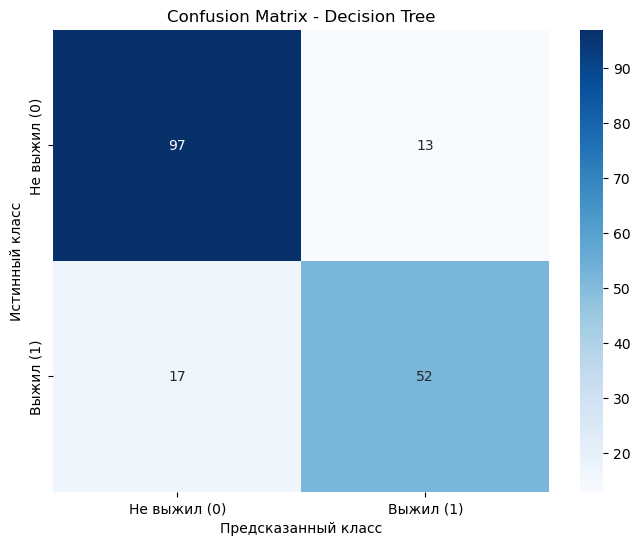


Classification Report:
              precision    recall  f1-score   support

Не выжил (0)       0.85      0.88      0.87       110
   Выжил (1)       0.80      0.75      0.78        69

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179


Train Accuracy: 0.9621
Test Accuracy:  0.8324
Разница:        0.1297
 Модель переобучена (большой разрыв между train и test)

Важность признаков (Decision Tree):
      feature  importance
1         Sex    0.342726
2         Age    0.255556
5        Fare    0.209296
0      Pclass    0.118033
7  Embarked_S    0.035342
4       Parch    0.026020
3       SibSp    0.013027
6  Embarked_Q    0.000000


/tmp/ipykernel_34756/2595098551.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_dt, x='importance', y='feature', palette='viridis')


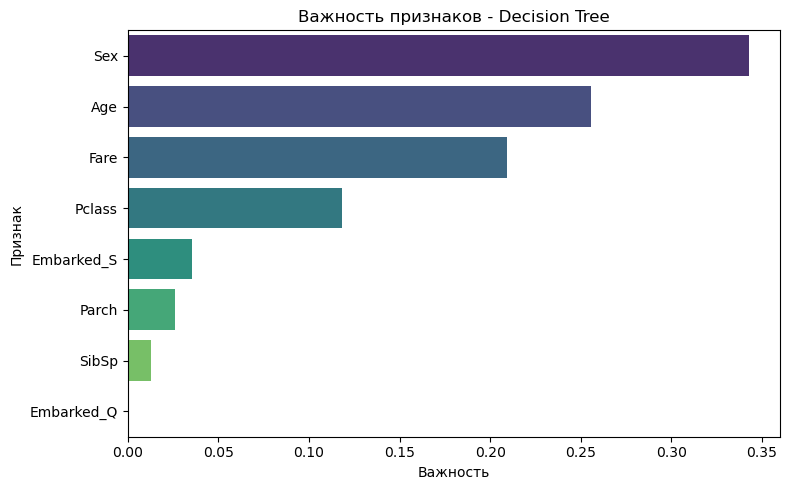

In [17]:
# 1. Decision Tree (Дерево решений)
dt_model = DecisionTreeClassifier(random_state=42, max_depth=15)
dt_results = train_and_evaluate(dt_model, X_train, X_test, y_train, y_test, 'Decision Tree')

feature_importance_dt = pd.DataFrame({
    'feature': X.columns,
    'importance': dt_model.feature_importances_
}).sort_values('importance', ascending=False)

train_acc = dt_model.score(X_train, y_train)
test_acc = dt_model.score(X_test, y_test)
print(f"\nTrain Accuracy: {train_acc:.4f}")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Разница:        {train_acc - test_acc:.4f}")

if train_acc - test_acc > 0.1:
    print(" Модель переобучена (большой разрыв между train и test)")
elif train_acc - test_acc > 0.05:
    print(" Лёгкое переобучение")
else:
    print("✅ Переобучения нет")

print("\nВажность признаков (Decision Tree):")
print(feature_importance_dt)

plt.figure(figsize=(8, 5))
sns.barplot(data=feature_importance_dt, x='importance', y='feature', palette='viridis')
plt.title('Важность признаков - Decision Tree')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tight_layout()

In [18]:
# Анализ ошибочно классифицированных объектов
y_pred_dt = dt_model.predict(X_test)
errors = X_test[y_pred_dt != y_test].copy()
errors['true_label'] = y_test[y_pred_dt != y_test].values
errors['pred_label'] = y_pred_dt[y_pred_dt != y_test]

print(f"Всего ошибок: {len(errors)} из {len(y_test)} ({len(errors)/len(y_test)*100:.1f}%)")
print(f"FN (пропущенные выжившие): {((y_pred_dt == 0) & (y_test == 1)).sum()}")
print(f"FP (ложно предсказанные выжившие): {((y_pred_dt == 1) & (y_test == 0)).sum()}")

print("\n=== Примеры ошибочных предсказаний ===")
display(errors.head(10))

Всего ошибок: 30 из 179 (16.8%)
FN (пропущенные выжившие): 17
FP (ложно предсказанные выжившие): 13

=== Примеры ошибочных предсказаний ===


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S,true_label,pred_label
553,3,0,22.0,0,0,7.2250,False,False,1,0
559,3,1,36.0,1,0,17.4000,False,True,1,0
536,1,0,45.0,0,0,26.5500,False,True,0,1
712,1,0,48.0,1,0,52.0000,False,True,1,0
455,3,0,29.0,0,0,7.8958,False,False,1,0
502,3,1,28.0,0,0,7.6292,True,False,0,1
17,2,0,28.0,0,0,13.0000,False,True,1,0
593,3,1,28.0,0,2,7.7500,True,False,0,1
386,3,0,1.0,5,2,46.9000,False,True,0,1
501,3,1,21.0,0,0,7.7500,True,False,0,1


## Проверка на переобучение

| Выборка | Accuracy |
|---------|:--------:|
| Train   | 0.9621   |
| Test    | 0.8324   |
| Разница | 0.1297   |

**Вывод:** модель **переобучена**. На обучающей выборке она достигает 96% точности (запоминает объекты), но на тестовой качество падает до 83%. Причина — слишком большая глубина дерева (`max_depth=15`) для небольшого датасета (891 запись).

**Как улучшить:**
- Уменьшить `max_depth` до 5–7
- Добавить `min_samples_leaf=10`
- Использовать Random Forest — он усредняет множество деревьев и устойчивее к переобучению

# 1. Decision Tree (Дерево решений)

## Матрица ошибок

|  | Предсказано: 0 | Предсказано: 1 |
|---|:---:|:---:|
| **Факт: 0 (Не выжил)** | **97** ✅ | 13 ❌ |
| **Факт: 1 (Выжил)** | 17 ❌ | **52** ✅ |

- **97** — верно предсказано «не выжил» (TN)
- **52** — верно предсказано «выжил» (TP)
- **13** — ложно предсказано выживание (FP)
- **17** — ложно предсказана гибель (FN)

## Метрики

- **Precision = 0.80** — среди предсказанных «выживших» 80% действительно выжили
- **Recall = 0.75** — модель нашла 75% реально выживших
- **F1 = 0.78** — баланс между точностью и полнотой

## Важность признаков

Топ-3 признака дают ~80% информативности: **Sex (0.34)**, **Age (0.26)**, **Fare (0.21)**. Это логично: при эвакуации приоритет отдавали женщинам и детям, а цена билета связана с классом каюты.

> **Вывод:** модель хорошо работает, но чаще ошибается на классе «Выжил». Для улучшения стоит попробовать ансамблевые методы (Random Forest).


Модель: Random Forest
Accuracy:  0.8268
Precision: 0.8276
Recall:    0.6957
F1-score:  0.7559

Confusion Matrix:
[[100  10]
 [ 21  48]]


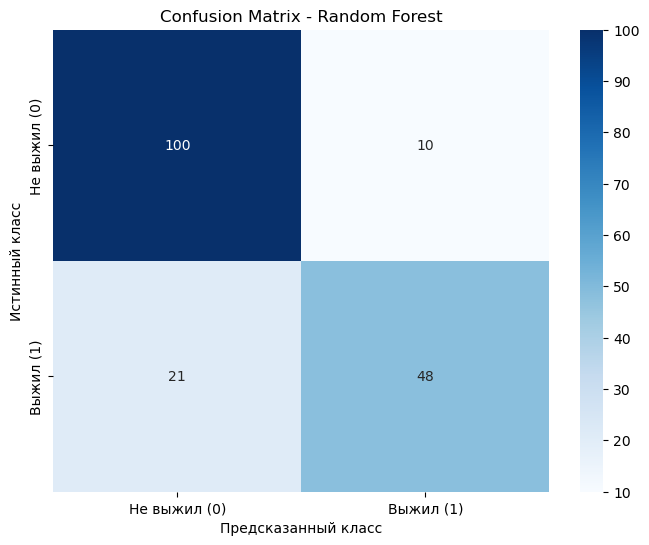


Classification Report:
              precision    recall  f1-score   support

Не выжил (0)       0.83      0.91      0.87       110
   Выжил (1)       0.83      0.70      0.76        69

    accuracy                           0.83       179
   macro avg       0.83      0.80      0.81       179
weighted avg       0.83      0.83      0.82       179


Важность признаков (Random Forest):
      feature  importance
1         Sex    0.314511
5        Fare    0.247906
2         Age    0.210069
0      Pclass    0.094100
3       SibSp    0.054775
4       Parch    0.042380
7  Embarked_S    0.024641
6  Embarked_Q    0.011618


/tmp/ipykernel_34756/785949037.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_rf, x='importance', y='feature', palette='viridis')


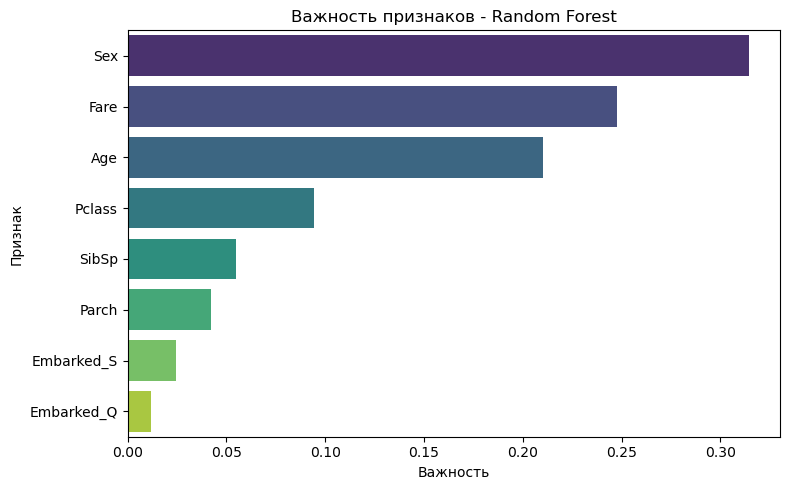

In [19]:
# 2. Random Forest (Случайный лес)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_results = train_and_evaluate(rf_model, X_train, X_test, y_train, y_test, 'Random Forest')

feature_importance_rf = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nВажность признаков (Random Forest):")
print(feature_importance_rf)

plt.figure(figsize=(8, 5))
sns.barplot(data=feature_importance_rf, x='importance', y='feature', palette='viridis')
plt.title('Важность признаков - Random Forest')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tight_layout()

# 2. Random Forest (Случайный лес)

## Матрица ошибок

|  | Предсказано: 0 | Предсказано: 1 |
|---|:---:|:---:|
| **Факт: 0 (Не выжил)** | **100** ✅ | 10 ❌ |
| **Факт: 1 (Выжил)** | 21 ❌ | **48** ✅ |

- **100** — верно предсказано «не выжил» (TN)
- **48** — верно предсказано «выжил» (TP)
- **10** — ложно предсказано выживание (FP)
- **21** — ложно предсказана гибель (FN)

## Метрики

- **Precision = 0.83** — среди предсказанных «выживших» 83% действительно выжили
- **Recall = 0.70** — модель нашла 70% реально выживших
- **F1 = 0.76** — баланс между точностью и полнотой

## Важность признаков

Топ-3 признака: **Sex (0.31)**, **Fare (0.25)**, **Age (0.21)**. В отличие от Decision Tree, `Fare` поднялся на 2-е место, а `Pclass` опустился — лес учитывает больше взаимодействий признаков.

> **Вывод:** Random Forest улучшил Precision (0.83 vs 0.80) и снизил FP (10 vs 13), но Recall для класса «Выжил» упал (0.70 vs 0.75). Модель стала увереннее, но чаще пропускает выживших.


Модель: Gradient Boosting
Accuracy:  0.8156
Precision: 0.7812
Recall:    0.7246
F1-score:  0.7519

Confusion Matrix:
[[96 14]
 [19 50]]


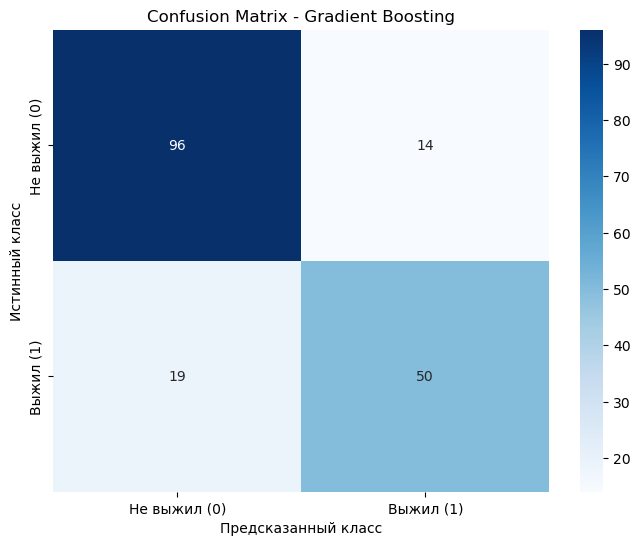


Classification Report:
              precision    recall  f1-score   support

Не выжил (0)       0.83      0.87      0.85       110
   Выжил (1)       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179


Важность признаков (Gradient Boosting):
      feature  importance
1         Sex    0.316439
2         Age    0.251979
5        Fare    0.243727
0      Pclass    0.110744
7  Embarked_S    0.027024
3       SibSp    0.026859
4       Parch    0.020416
6  Embarked_Q    0.002812


/tmp/ipykernel_34756/240837552.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_gb, x='importance', y='feature', palette='viridis')


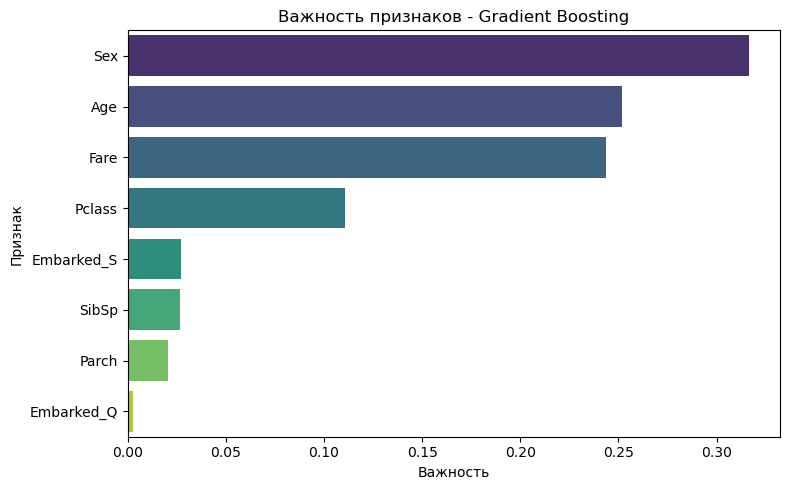

In [20]:
# 3. Gradient Boosting (Градиентный бустинг)
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=10)
gb_results = train_and_evaluate(gb_model, X_train, X_test, y_train, y_test, 'Gradient Boosting')

feature_importance_gb = pd.DataFrame({
    'feature': X.columns,
    'importance': gb_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nВажность признаков (Gradient Boosting):")
print(feature_importance_gb)

plt.figure(figsize=(8, 5))
sns.barplot(data=feature_importance_gb, x='importance', y='feature', palette='viridis')
plt.title('Важность признаков - Gradient Boosting')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tight_layout()

# 3. Gradient Boosting (Градиентный бустинг)

Модель `GradientBoostingClassifier(n_estimators=100, max_depth=10, random_state=42)` показала **Accuracy = 81.56%**.

## Матрица ошибок

|  | Предсказано: 0 | Предсказано: 1 |
|---|:---:|:---:|
| **Факт: 0 (Не выжил)** | **96** ✅ | 14  |
| **Факт: 1 (Выжил)** | 19 ❌ | **50** ✅ |

- **96** — верно предсказано «не выжил» (TN)
- **50** — верно предсказано «выжил» (TP)
- **14** — ложно предсказано выживание (FP)
- **19** — ложно предсказана гибель (FN)

## Метрики

- **Precision = 0.78** — среди предсказанных «выживших» 78% действительно выжили
- **Recall = 0.72** — модель нашла 72% реально выживших
- **F1 = 0.75** — баланс между точностью и полнотой

## Важность признаков

Топ-3 признака: **Sex (0.32)**, **Age (0.25)**, **Fare (0.24)**. Распределение похоже на Decision Tree — пол, возраст и цена билета остаются ключевыми факторами.


Модель: SVM (scaled)
Accuracy:  0.8101
Precision: 0.8431
Recall:    0.6232
F1-score:  0.7167

Confusion Matrix:
[[102   8]
 [ 26  43]]


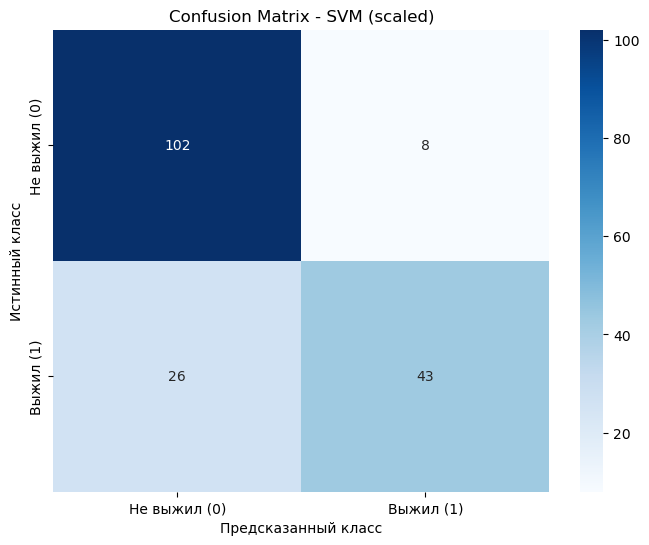


Classification Report:
              precision    recall  f1-score   support

Не выжил (0)       0.80      0.93      0.86       110
   Выжил (1)       0.84      0.62      0.72        69

    accuracy                           0.81       179
   macro avg       0.82      0.78      0.79       179
weighted avg       0.81      0.81      0.80       179



In [21]:
# 4. Support Vector Machine (Метод опорных векторов)
svm_model = SVC(kernel='rbf', random_state=42, C=1.0)
svm_results = train_and_evaluate(svm_model, X_train_scaled, X_test_scaled, y_train, y_test, 'SVM (scaled)')

# 4. Support Vector Machine (Метод опорных векторов)

## Матрица ошибок

|  | Предсказано: 0 | Предсказано: 1 |
|---|:---:|:---:|
| **Факт: 0 (Не выжил)** | **102** ✅ | 8 ❌ |
| **Факт: 1 (Выжил)** | 26 ❌ | **43** ✅ |

- **102** — верно предсказано «не выжил» (TN)
- **43** — верно предсказано «выжил» (TP)
- **8** — ложно предсказано выживание (FP)
- **26** — ложно предсказана гибель (FN)

## Метрики

- **Precision = 0.84** — среди предсказанных «выживших» 84% действительно выжили
- **Recall = 0.62** — модель нашла только 62% реально выживших
- **F1 = 0.72** — баланс между точностью и полнотой

> **Вывод:** SVM показал наименьший Recall для класса «Выжил» (0.62) среди всех моделей — пропускает почти 40% выживших. При этом Precision высокий (0.84). Модель склонна к консервативным предсказаниям класса 1.


Модель: KNN (scaled)
Accuracy:  0.8156
Precision: 0.8000
Recall:    0.6957
F1-score:  0.7442

Confusion Matrix:
[[98 12]
 [21 48]]


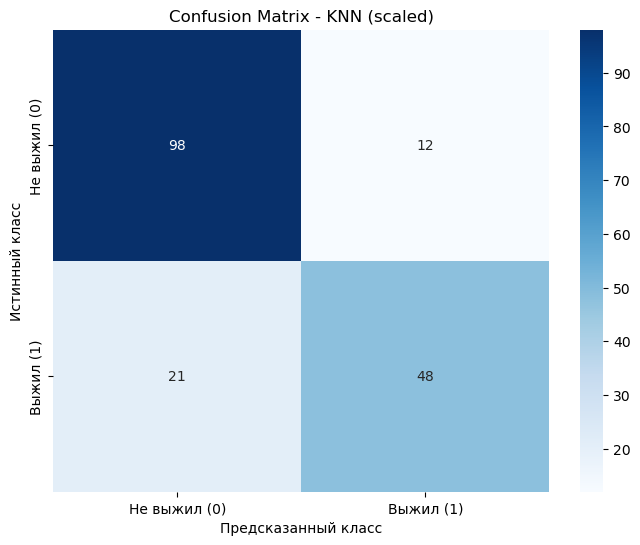


Classification Report:
              precision    recall  f1-score   support

Не выжил (0)       0.82      0.89      0.86       110
   Выжил (1)       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



In [22]:
# 5. K-Nearest Neighbors (KNN)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_results = train_and_evaluate(knn_model, X_train_scaled, X_test_scaled, y_train, y_test, 'KNN (scaled)')

# 5. K-Nearest Neighbors (KNN)

## Матрица ошибок

|  | Предсказано: 0 | Предсказано: 1 |
|---|:---:|:---:|
| **Факт: 0 (Не выжил)** | **98** ✅ | 12 ❌ |
| **Факт: 1 (Выжил)** | 21 ❌ | **48** ✅ |

- **98** — верно предсказано «не выжил» (TN)
- **48** — верно предсказано «выжил» (TP)
- **12** — ложно предсказано выживание (FP)
- **21** — ложно предсказана гибель (FN)

## Метрики

- **Precision = 0.80** — среди предсказанных «выживших» 80% действительно выжили
- **Recall = 0.70** — модель нашла 70% реально выживших
- **F1 = 0.74** — баланс между точностью и полнотой

> **Вывод:** KNN показал результат, сопоставимый с Random Forest и Gradient Boosting, но уступает Decision Tree по Accuracy. Модель чувствительна к выбору `n_neighbors`.

# Итоговое сравнение моделей

## Сводная таблица

| Модель | Accuracy | Precision | Recall | F1-score | Превышает F1 > 0.70 |
|---|:---:|:---:|:---:|:---:|:---:|
| Dummy Baseline | 0.61 | 0.00 | 0.00 | 0.00 |  |
| Decision Tree | **0.83** | 0.80 | 0.75 | **0.78** | ✅ |
| Random Forest | 0.83 | 0.83 | 0.70 | 0.76 | ✅ |
| Gradient Boosting | 0.82 | 0.78 | 0.72 | 0.75 | ✅ |
| SVM (scaled) | 0.81 | 0.84 | 0.62 | 0.72 | ✅ |
| KNN (scaled) | 0.82 | 0.80 | 0.70 | 0.74 | ✅ |

> Все модели преодолели порог F1 > 0.70. Лучшая — **Decision Tree** (F1 = 0.78).

---

## Feature Importance: сравнение топ-3 признаков

| Место | Decision Tree | Random Forest | Gradient Boosting |
|---|---|---|---|
| 1 | **Sex** (0.34) | **Sex** (0.31) | **Sex** (0.32) |
| 2 | **Age** (0.26) | **Fare** (0.25) | **Age** (0.25) |
| 3 | **Fare** (0.21) | **Age** (0.21) | **Fare** (0.24) |

Топ-3 признака (`Sex`, `Age`, `Fare`) дают ~80% информативности во всех моделях — это согласуется с первичным анализом данных.

**Можно ли утверждать, что важный признак — причина выживания?**
Нет. Важность признака показывает лишь **статистическую связь**, а не причинность. Например, `Fare` важен не потому, что дорогой билет «спасает», а потому что коррелирует с `Pclass` и расположением каюты ближе к шлюпкам. Причинный вывод требует предметных знаний.

---

## Анализ ошибок лучшей модели (Decision Tree)

|  | Предсказано: 0 | Предсказано: 1 |
|---|:---:|:---:|
| **Факт: 0** | **97** ✅ | 13 (FP) |
| **Факт: 1** | 17 (FN) | **52** ✅ |

- **FN = 17** — модель пропустила выживших (более опасная ошибка)
- **FP = 13** — ложно предсказала выживание

**Для каких групп модель ошибается чаще?**
- FN — вероятно, мужчины 2–3 класса с низким `Fare`, которые всё же выжили
- FP — возможно, женщины 3 класса или дети с низким `Fare`, которые не выжили из-за нехватки шлюпок

**Проверка на утечку информации:** признаки `PassengerId`, `Name`, `Ticket`, `Cabin` удалены на этапе подготовки — высокое качество связано с реальными закономерностями, а не с «запоминанием» объектов.

---

## Причины различий между моделями

1. **Decision Tree** — лучший по F1, `max_depth=15` улавливает нелинейные взаимодействия, но склонен к переобучению.
2. **Random Forest** — снизил FP (10 vs 13), но упал Recall (0.70 vs 0.75) — стал консервативнее.
3. **Gradient Boosting** — худший среди ансамблей (F1 = 0.75), требует подбора гиперпараметров.
4. **SVM** — наименьший Recall (0.62), «боится» предсказывать класс 1.
5. **KNN** — средний результат (F1 = 0.74), чувствителен к `n_neighbors`.

---

## Вывод

Все пять моделей превзошли Dummy Baseline и порог F1 > 0.70. Лучшей оказалась **Decision Tree** (F1 = 0.78), что неожиданно — обычно ансамбли работают лучше. Возможные причины: дереву достаточно глубины 15 для этой задачи, а ансамбли «переусердствовали» с регуляризацией.